# 13 — Features de ritmo

**Objetivo:** probar si sumar las features de ritmo de la notebook 04 a las
features espectrales corregidas (notebook 11) mejora la detección de
arritmias, que en las notebooks 10 y 11 quedaron como lo más difícil. Al
terminar deberías poder:
- decir qué mide cada una de las cinco features de ritmo;
- decir si sumarlas mejora el resultado, en general y por tipo de patología;
- explicar por qué un modelo que separa "normal contra patológico" aprovecha
  mal estas features;
- explicar por qué el detector simple de la notebook 04 no alcanza, y qué
  haría falta.

Solo cardíacos: el ritmo es una pregunta cardíaca. Las reglas son las de la
notebook 11 (los cuatro modelos con `class_weight`, validación cruzada
estratificada de 5 particiones repetida 3 veces, umbral 0,5) y la comparación
es contra la línea de base de la 11 con el bootstrap pareado.

*(La notebook tarda unos 2 minutos en correr entera.)*

In [1]:
import sys
import warnings
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_predict
from sklearn.svm import SVC
from xgboost import XGBClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.evaluation import make_pipeline
from src.paths import AUDIO, OUT_DIR

warnings.filterwarnings("ignore")

SR = 4000
NO_FEATURES = ["file_id", "label", "label_binary"]
RITMO = ["fc_lpm", "regularidad", "eventos_por_s", "cv_intervalos", "irregularidad"]
SEMILLA = 0
REPETICIONES = 3
MODELOS = ["Regresión logística", "SVM-RBF", "Random forest", "XGBoost"]

AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#898781", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6})


def modelos(y):
    """Los cuatro modelos de las notebooks 10 y 11."""
    peso_xgb = (y == 0).sum() / (y == 1).sum()
    return {
        "Regresión logística": make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"),
                                             "class_weight"),
        "SVM-RBF": make_pipeline(SVC(kernel="rbf", class_weight="balanced"), "class_weight"),
        "Random forest": make_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                              random_state=SEMILLA), "class_weight"),
        "XGBoost": make_pipeline(XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.9,
                                               scale_pos_weight=peso_xgb, eval_metric="logloss",
                                               random_state=SEMILLA, n_jobs=1), "class_weight"),
    }


def puntajes(modelo, X, y, cv, grupos=None):
    if hasattr(modelo, "predict_proba"):
        return cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="predict_proba")[:, 1]
    return 1 / (1 + np.exp(-cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="decision_function")))


def prob_validacion(modelo, X, y):
    return [puntajes(modelo, X, y, StratifiedKFold(5, shuffle=True, random_state=s)) for s in range(REPETICIONES)]


def auc_medio(y, probs):
    return np.mean([roc_auc_score(y, p) for p in probs])


def metricas(y, probs, umbral=0.5):
    filas = []
    for p in probs:
        tn, fp, fn, tp = confusion_matrix(y, p >= umbral, labels=[0, 1]).ravel()
        sens, esp = tp / (tp + fn), tn / (tn + fp)
        filas.append({"AUC": roc_auc_score(y, p), "sens.": sens, "esp.": esp, "exact. bal.": (sens + esp) / 2})
    return pd.DataFrame(filas).mean()


def dif_pareada(y, p_nueva, p_vieja, n=1000):
    """Diferencia de AUC (nueva − vieja) e IC 95 % por bootstrap pareado (notebook 11)."""
    rng = np.random.default_rng(SEMILLA)
    valores = []
    while len(valores) < n:
        m = rng.integers(0, len(y), len(y))
        if len(np.unique(y[m])) == 2:
            valores.append(auc_medio(y[m], [p[m] for p in p_nueva]) - auc_medio(y[m], [p[m] for p in p_vieja]))
    return auc_medio(y, p_nueva) - auc_medio(y, p_vieja), np.percentile(valores, [2.5, 97.5])

## 1. Las features de ritmo (recordatorio de la notebook 04)

Todas salen de la **envolvente** de energía (un "bulto" por cada ruido
cardíaco) y de los **picos** que detecta en ella un detector simple:

| Feature | Qué mide | Qué esperaríamos en una arritmia |
|---|---|---|
| `fc_lpm` | frecuencia cardíaca estimada con la autocorrelación de la envolvente | alta en la taquicardia |
| `regularidad` | qué tan periódico es el sonido (el pico de la autocorrelación) | baja en la fibrilación auricular |
| `eventos_por_s` | ruidos detectados por segundo | alto en la taquicardia |
| `cv_intervalos` | variación de los intervalos entre ruidos (desvío / media) | alto si el ritmo es irregular |
| `irregularidad` | cuánto cambia cada intervalo respecto del de dos lugares antes (sístole con sístole, diástole con diástole) | alta en la fibrilación auricular |

La envolvente se calcula sobre la banda de 25–400 Hz. En la notebook 12 esa
banda empeoraba la **clasificación**, pero acá se usa para lo que fue pensada:
**encontrar R1 y R2**.

Las guardamos en la notebook 04 (`outputs/hs_ritmo.csv`). Las unimos a la línea
de base de la notebook 11 y armamos tres conjuntos: las 101 espectrales, las
5 de ritmo solas, y las 106 juntas.

In [2]:
espectrales = pd.read_csv(OUT_DIR / "hs_features_corregidas.csv")
ritmo = pd.read_csv(OUT_DIR / "hs_ritmo.csv")
df = espectrales.merge(ritmo[["file_id"] + RITMO], on="file_id", how="left", validate="one_to_one")
assert df[RITMO].notna().all().all() and (df["file_id"] == espectrales["file_id"]).all()

y = df["label_binary"].values
tipo = df["label"].values
caso = df["file_id"].str.split("_").str[:2].str.join("_").values
CONJUNTOS = {"espectrales (101)": df.drop(columns=NO_FEATURES + RITMO),
             "ritmo (5)": df[RITMO],
             "espectrales + ritmo (106)": df.drop(columns=NO_FEATURES)}
for nombre, X in CONJUNTOS.items():
    print(f"{nombre}: {X.shape[1]} features, {X.shape[0]} grabaciones")

espectrales (101): 101 features, 50 grabaciones
ritmo (5): 5 features, 50 grabaciones
espectrales + ritmo (106): 106 features, 50 grabaciones


## 2. ¿Qué separa cada feature sola?

Primero, cada feature por separado, contra los normales, para las tres
arritmias. Como referencia, la mediana de las 101 espectrales. La medimos
como en la notebook 03: max(AUC, 1 − AUC), que no depende de la dirección.

In [3]:
def fuerza(valores, etiquetas):
    a = roc_auc_score(etiquetas, valores)
    return max(a, 1 - a)


filas = []
for t in ["Atrial Fibrillation", "AV Block", "Tachycardia"]:
    m = np.isin(tipo, ["Normal", t])
    etiquetas = (tipo[m] == t).astype(int)
    fila = {"tipo": f"{t} ({etiquetas.sum()})",
            "101 espectrales (mediana)": CONJUNTOS["espectrales (101)"][m].apply(lambda c: fuerza(c, etiquetas)).median()}
    fila.update({c: fuerza(df.loc[m, c], etiquetas) for c in RITMO})
    filas.append(fila)
print(pd.DataFrame(filas).round(2).to_string(index=False))

print("\nMediana de cada feature de ritmo, por tipo:")
print(df.groupby("label")[RITMO].median().round(2).to_string())

                   tipo  101 espectrales (mediana)  fc_lpm  regularidad  eventos_por_s  cv_intervalos  irregularidad
Atrial Fibrillation (4)                       0.64    0.58         0.81           0.64           0.81           0.72
           AV Block (3)                       0.63    0.74         0.63           0.67           0.78           0.52
        Tachycardia (3)                       0.59    0.78         0.52           1.00           1.00           1.00

Mediana de cada feature de ritmo, por tipo:
                       fc_lpm  regularidad  eventos_por_s  cv_intervalos  irregularidad
label                                                                                  
AV Block                71.43         0.18           3.00           0.65           0.36
Atrial Fibrillation     41.31         0.15           3.93           0.34           0.29
Early Systolic Murmur   71.86         0.26           4.20           0.33           0.33
Late Diastolic Murmur   72.29         0.78     

**Cómo leerlo:**
- La **taquicardia** se separa perfecto de los normales con tres features
  (eventos por segundo, variación de los intervalos e irregularidad).
- La **fibrilación auricular** y el **bloqueo AV** se separan bastante con
  algunas (0,7–0,8). Pero mirá las medianas: la fibrilación auricular tiene
  una variación de los intervalos **menor** que los normales (0,34 contra
  0,44), al revés de lo esperable en un ritmo irregular. Y los soplos tienen
  una regularidad tan baja como la fibrilación (0,17–0,26 contra 0,15), como
  vimos en la notebook 05: el soplo "rellena" la envolvente.

O sea: algunas features separan, pero **no necesariamente por la razón que
buscábamos**. Volvemos sobre esto en la sección 5.

## 3. ¿Sumar el ritmo mejora el modelo?

In [4]:
probs = {}
for conjunto, X in CONJUNTOS.items():
    for nombre, modelo in modelos(y).items():
        probs[(conjunto, nombre)] = prob_validacion(modelo, X, y)

tabla = pd.concat({c: pd.DataFrame({n: metricas(y, probs[(c, n)]) for n in MODELOS}).T for c in CONJUNTOS}, axis=1)
print(tabla.round(2).to_string())

print("\nEspectrales + ritmo contra espectrales solas (bootstrap pareado):")
filas = []
for nombre in MODELOS:
    d, (bajo, alto) = dif_pareada(y, probs[("espectrales + ritmo (106)", nombre)], probs[("espectrales (101)", nombre)])
    filas.append({"modelo": nombre, "diferencia de AUC": d, "IC 95 %": f"{bajo:+.3f} a {alto:+.3f}"})
print(pd.DataFrame(filas).round(3).to_string(index=False))

                    espectrales (101)                         ritmo (5)                         espectrales + ritmo (106)                        
                                  AUC sens.  esp. exact. bal.       AUC sens.  esp. exact. bal.                       AUC sens.  esp. exact. bal.
Regresión logística              0.83  0.86  0.70        0.78      0.64  0.61  0.52        0.56                      0.83  0.87  0.74        0.81
SVM-RBF                          0.83  0.93  0.41        0.67      0.69  0.57  0.78        0.67                      0.83  0.95  0.44        0.70
Random forest                    0.82  0.98  0.00        0.49      0.60  0.95  0.07        0.51                      0.83  0.98  0.00        0.49
XGBoost                          0.75  0.83  0.41        0.62      0.55  0.62  0.44        0.53                      0.75  0.83  0.41        0.62

Espectrales + ritmo contra espectrales solas (bootstrap pareado):


             modelo  diferencia de AUC         IC 95 %
Regresión logística              0.008 -0.006 a +0.023
            SVM-RBF              0.001 -0.015 a +0.020
      Random forest              0.009 -0.023 a +0.042
            XGBoost             -0.002 -0.009 a +0.000


**Sumar el ritmo no cambia nada:** las diferencias de AUC van de −0,002 a
+0,009, y todos los intervalos incluyen el 0. Las 5 features de ritmo
**solas** separan bastante menos que las espectrales (0,55–0,69 contra
0,75–0,83).

## 4. ¿Y por tipo de patología?

El AUC de cada tipo contra los normales, con la regresión logística y el
random forest:

In [5]:
normales = tipo == "Normal"
TIPOS = pd.Series(tipo[~normales]).value_counts().index


def auc_tipo(conjunto, nombre, t):
    etiquetas = np.r_[np.zeros(normales.sum()), np.ones((tipo == t).sum())]
    return auc_medio(etiquetas, [np.r_[p[normales], p[tipo == t]] for p in probs[(conjunto, nombre)]])


for nombre in ["Regresión logística", "Random forest"]:
    t = pd.DataFrame({c: {f"{t} ({(tipo == t).sum()})": auc_tipo(c, nombre, t) for t in TIPOS} for c in CONJUNTOS})
    print(f"\n{nombre}")
    print(t.round(2).to_string())


Regresión logística
                           espectrales (101)  ritmo (5)  espectrales + ritmo (106)
Mid Systolic Murmur (7)                 0.74       0.68                       0.76
Late Diastolic Murmur (6)               0.90       0.96                       0.91
Early Systolic Murmur (6)               0.91       0.69                       0.91
S3 (5)                                  0.87       0.68                       0.87
Late Systolic Murmur (5)                0.90       0.34                       0.90
Atrial Fibrillation (4)                 0.70       0.55                       0.74
Tachycardia (3)                         0.86       1.00                       0.88
AV Block (3)                            0.68       0.16                       0.67
S4 (2)                                  0.80       0.50                       0.81



Random forest
                           espectrales (101)  ritmo (5)  espectrales + ritmo (106)
Mid Systolic Murmur (7)                 0.69       0.49                       0.68
Late Diastolic Murmur (6)               0.99       0.86                       0.98
Early Systolic Murmur (6)               0.94       0.55                       0.95
S3 (5)                                  0.85       0.58                       0.91
Late Systolic Murmur (5)                0.98       0.51                       0.98
Atrial Fibrillation (4)                 0.69       0.48                       0.70
Tachycardia (3)                         0.72       0.89                       0.76
AV Block (3)                            0.57       0.48                       0.54
S4 (2)                                  0.78       0.63                       0.79


**Cómo leerlo (regresión logística):**
- Con el **ritmo solo**, la taquicardia queda perfecta (1,00), pero el
  **bloqueo AV queda en 0,16**: el modelo lo ordena **al revés**, más "normal"
  que los normales.
- Al **sumar** el ritmo a las espectrales, la fibrilación auricular apenas
  sube (de 0,70 a 0,74) y el resto queda igual: la información de ritmo se
  diluye entre las 101 espectrales, que ya reconocían la taquicardia (0,86).

## 5. ¿Por qué no ayuda?

### 5.1 Un solo "patológico" mezcla direcciones opuestas

El modelo aprende a separar **normal contra patológico**, y la mayoría de los
patológicos (los soplos, la taquicardia) tienen **más** eventos por segundo y
una variación de los intervalos **menor** que los normales. El bloqueo AV va
**para el otro lado**:

In [6]:
grupos = pd.Series(np.where(np.char.find(tipo.astype(str), "Murmur") >= 0, "soplos (todos)", tipo), index=df.index)
print(df.groupby(grupos)[["eventos_por_s", "cv_intervalos"]].median()
      .loc[["Normal", "soplos (todos)", "Tachycardia", "AV Block", "Atrial Fibrillation"]].round(2).to_string())

                     eventos_por_s  cv_intervalos
Normal                        3.60           0.44
soplos (todos)                3.87           0.34
Tachycardia                   4.67           0.19
AV Block                      3.00           0.65
Atrial Fibrillation           3.93           0.34


Un modelo lineal da a cada feature **una sola dirección**: "más eventos por
segundo = más patológico". No puede aprender "distinto del normal hacia
cualquier lado". Por eso pone al bloqueo AV (menos eventos, intervalos más
desparejos) del lado normal. Un modelo de árboles podría aprenderlo, pero con
3 grabaciones de bloqueo AV no tiene de dónde.

### 5.2 El detector simple no encuentra bien R1 y R2

Las grabaciones de un mismo caso son **el mismo sonido del maniquí**, grabado
en distintos focos: la frecuencia cardíaca no debería cambiar entre ellas.
Mirá lo que estima el detector en los dos casos normales (`F_N` y `M_N`):

In [7]:
print(df.loc[normales, ["file_id"] + RITMO].round(2).to_string(index=False))

 file_id  fc_lpm  regularidad  eventos_por_s  cv_intervalos  irregularidad
  F_N_RC   32.43         0.15           3.60           0.44           0.40
  F_N_LC   71.43         0.17           4.07           0.35           0.27
M_N_RUSB  115.38         0.34           3.33           0.52           0.41
F_N_LUSB   71.43         0.59           3.33           0.47           0.32
F_N_LLSB   35.93         0.59           3.47           0.48           0.47
   F_N_A   71.43         0.50           3.00           0.49           0.34
F_N_RUSB   72.29         0.57           3.67           0.41           0.33
  M_N_LC   41.10         0.18           4.33           0.32           0.25
M_N_LLSB   62.50         0.15           3.80           0.34           0.27


Dentro de un **mismo** caso, la frecuencia estimada cambia muchísimo según el
foco: de 32 a 72 lpm en `F_N` y de 41 a 115 lpm en `M_N`. La regularidad va de
0,15 a 0,59. Con normales tan "variables" para el detector, ninguna feature de
ritmo puede distinguirlos bien de una arritmia. Es lo que anticipaba la notebook 04: con muchos picos chicos, la
envolvente no deja reconocer los pares R1-R2.

**Una prueba más, desde la semiología.** En la fibrilación auricular y en el
bloqueo AV completo, la intensidad de R1 **cambia de latido a latido**.
Podemos medirlo con la altura de cada pico, comparándolo con el de dos
lugares antes (R1 con R1, R2 con R2), igual que la `irregularidad` hace con
los intervalos. La probamos una sola vez, con este argumento fijado antes:

In [8]:
FS_ENV = 100   # valores de la envolvente por segundo (notebook 04)


def envolvente(y):
    """Envolvente de energía de la notebook 04, sin estandarizar (para medir alturas)."""
    y = signal.sosfiltfilt(signal.butter(4, (25, 400), "bandpass", fs=SR, output="sos"), y)
    y = y / np.sqrt(np.mean(y ** 2))
    e = signal.sosfiltfilt(signal.butter(4, 20, "lowpass", fs=SR, output="sos"), np.abs(y))
    return e[:: SR // FS_ENV]


def picos(e):
    """El detector de la notebook 04 (sobre la envolvente estandarizada)."""
    z = (e - e.mean()) / e.std()
    p, _ = signal.find_peaks(z, distance=int(0.15 * FS_ENV), prominence=0.5)
    return p


def variabilidad_intensidad(y):
    e = envolvente(y)
    a = e[picos(e)]
    return np.median(np.abs(a[2:] - a[:-2]) / ((a[2:] + a[:-2]) / 2))


intensidad = pd.Series([variabilidad_intensidad(librosa.load(AUDIO["HS"] / f"{fid}.wav", sr=SR)[0])
                        for fid in df["file_id"]], index=df.index)
print("Variabilidad de la intensidad (mediana por tipo):")
print(intensidad.groupby(tipo).median().round(2).to_string())

Variabilidad de la intensidad (mediana por tipo):
AV Block                 0.50
Atrial Fibrillation      0.36
Early Systolic Murmur    0.47
Late Diastolic Murmur    0.07
Late Systolic Murmur     0.35
Mid Systolic Murmur      0.32
Normal                   0.53
S3                       0.41
S4                       0.35
Tachycardia              0.16


Tampoco funciona: los **normales** dan la variabilidad **más alta** (0,53),
más que la fibrilación auricular (0,36). El problema no es qué feature
calculamos, sino que el detector no encuentra R1 y R2 de forma confiable: si
los picos no son los ruidos cardíacos, cualquier medida sobre ellos es ruido.

### 5.3 Muy pocas arritmias

Hay 4 grabaciones de fibrilación auricular, 3 de bloqueo AV y 3 de
taquicardia, de 1 o 2 casos cada una. Aun con buenas features, es muy poco
para que un modelo aprenda patrones de ritmo.

## 6. La validación por caso, con el control de pseudo-casos

Con la regresión logística y el SVM-RBF, para las espectrales solas y con el
ritmo:

In [9]:
def pseudo_casos(caso, y, rng):
    """Grupos al azar con los mismos tamaños y la misma clase que los casos reales (notebook 07)."""
    nuevo = np.empty(len(caso), dtype=object)
    for clase in [0, 1]:
        indices = rng.permutation(np.where(y == clase)[0])
        tamanios = pd.Series(caso[y == clase]).value_counts().values
        inicio = 0
        for j, t in enumerate(tamanios):
            nuevo[indices[inicio:inicio + t]] = f"pseudo_{clase}_{j}"
            inicio += t
    return nuevo


rng = np.random.default_rng(SEMILLA)
sorteos = [pseudo_casos(caso, y, rng) for _ in range(5)]
filas = []
for conjunto in ["espectrales (101)", "espectrales + ritmo (106)"]:
    X = CONJUNTOS[conjunto]
    for nombre in ["Regresión logística", "SVM-RBF"]:
        modelo = modelos(y)[nombre]
        pseudo = [roc_auc_score(y, puntajes(modelo, X, y, LeaveOneGroupOut(), g)) for g in sorteos]
        real = roc_auc_score(y, puntajes(modelo, X, y, LeaveOneGroupOut(), caso))
        filas.append({"conjunto": conjunto, "modelo": nombre, "pseudo-caso (media)": np.mean(pseudo),
                      "pseudo-caso (mín–máx)": f"{np.min(pseudo):.2f}–{np.max(pseudo):.2f}", "caso real": real,
                      "¿fuga?": "sí" if real < np.min(pseudo) else "no medible"})
print(pd.DataFrame(filas).round(3).to_string(index=False))

                 conjunto              modelo  pseudo-caso (media) pseudo-caso (mín–máx)  caso real     ¿fuga?
        espectrales (101) Regresión logística                0.715             0.58–0.82      0.732 no medible
        espectrales (101)             SVM-RBF                0.629             0.43–0.74      0.607 no medible
espectrales + ritmo (106) Regresión logística                0.710             0.58–0.82      0.743 no medible
espectrales + ritmo (106)             SVM-RBF                0.631             0.44–0.75      0.604 no medible


Sin fuga medible, con o sin ritmo, y sin cambios en la validación por caso.

## 7. Qué haría falta

Para medir el ritmo de verdad hay que **segmentar** el sonido cardíaco:
identificar cada R1, sístole, R2 y diástole. El método de referencia es el de
Springer, Tarassenko y Clifford (2016), que combina una regresión logística
con un modelo oculto de semi-Markov y fue la base del desafío PhysioNet/CinC
2016. Con una segmentación así se podrían medir:
- los intervalos **R1 a R1** (el ciclo cardíaco) y su irregularidad, para la
  fibrilación auricular;
- la **intensidad de cada R1**, para el bloqueo AV completo y la fibrilación;
- la duración de la sístole y la diástole, y la frecuencia, para la
  taquicardia.

Queda como **trabajo futuro**. Con 4 fibrilaciones auriculares y 3 bloqueos AV,
además, este dataset no alcanzaría para validarlo bien.

## 8. Qué nos llevamos

1. **Las features de ritmo de la notebook 04 no mejoran** el modelo, ni en
   general ni en las arritmias. No las sumamos: agregan features sin agregar
   información.
2. **Por qué:** un solo "patológico" mezcla arritmias que van en direcciones
   opuestas, el detector simple no encuentra R1 y R2 de forma confiable (un
   mismo caso normal da de 32 a 72 lpm según el foco) y hay muy pocas
   arritmias.
3. **Para la tesis:** las arritmias son la principal **limitación** del
   clasificador cardíaco, con una explicación concreta y una propuesta
   concreta de trabajo futuro (la segmentación).

## 9. Cómo explicárselo a tu directora (en 5 frases)

1. *"Sumé cinco features de ritmo (frecuencia, regularidad, eventos por
   segundo y dos medidas de irregularidad) a las espectrales corregidas, y no
   cambió nada: las diferencias de AUC están entre −0,002 y +0,009."*
2. *"Solas, detectan perfecto la taquicardia, pero ordenan al revés el bloqueo
   AV: el modelo aprende que 'más eventos por segundo es patológico', y el
   bloqueo AV va para el otro lado."*
3. *"El detector de picos es el cuello de botella: un mismo caso normal del
   maniquí da frecuencias estimadas de 32 a 72 lpm según el foco."*
4. *"Tampoco funcionó una feature motivada por la semiología, la variabilidad
   de la intensidad de R1: los normales salen más variables que las
   fibrilaciones."*
5. *"Para las arritmias haría falta segmentar R1 y R2 (por ejemplo, con el
   método de Springer et al., 2016), y más grabaciones; queda como trabajo
   futuro."*

## 10. Tu turno

Mirá la envolvente y los picos detectados en dos grabaciones **del mismo caso
normal** (`F_N`), en dos focos distintos. El detector les estima 32 y 71 lpm.
¿Dónde se equivoca? ¿Reconocés vos los pares R1-R2?

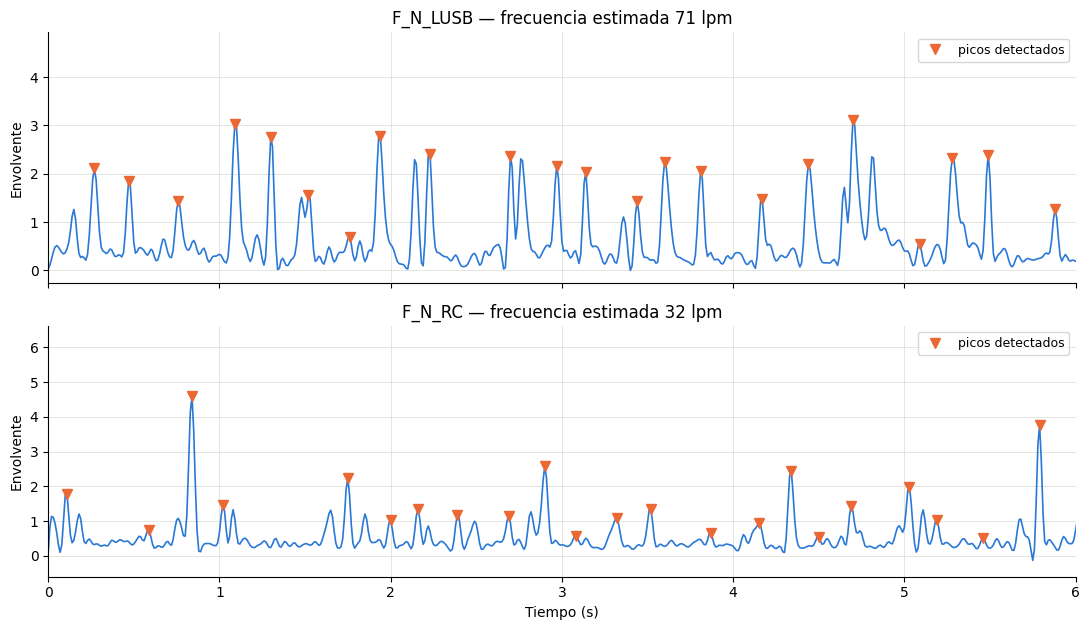

In [10]:
GRABACIONES = ["F_N_LUSB", "F_N_RC"]   # probá otras: un normal y una fibrilación auricular (F_AF_A)
SEGUNDOS = 6

fig, axes = plt.subplots(len(GRABACIONES), 1, figsize=(11, 3.2 * len(GRABACIONES)), sharex=True)
for ax, fid in zip(np.atleast_1d(axes), GRABACIONES):
    e = envolvente(librosa.load(AUDIO["HS"] / f"{fid}.wav", sr=SR)[0])
    p = picos(e)
    t = np.arange(len(e)) / FS_ENV
    ax.plot(t, e, color=AZUL, lw=1.2)
    ax.plot(t[p], e[p], "v", color=NARANJA, ms=7, label="picos detectados")
    fc = df.loc[df["file_id"] == fid, "fc_lpm"].iloc[0]
    ax.set(title=f"{fid} — frecuencia estimada {fc:.0f} lpm", ylabel="Envolvente", xlim=(0, SEGUNDOS))
    ax.legend(loc="upper right", fontsize=9)
np.atleast_1d(axes)[-1].set_xlabel("Tiempo (s)")
fig.tight_layout()

**Lo que se ve:** en `F_N_LUSB` hay pares de picos bastante regulares (R1 y
R2), y el detector marca la mayoría, aunque se saltea algunos. En `F_N_RC`,
en cambio, hay unos pocos picos muy altos y aislados (cerca de 0,8 s y de
5,8 s), que podrían ser roces o golpes del estetoscopio más que ruidos
cardíacos, y entre ellos muchos picos chicos de alturas parecidas: los pares
R1-R2 casi no se reconocen. La autocorrelación queda dominada por esos
picos, y la frecuencia estimada (32 lpm) no tiene sentido. Es el mismo sonido
normal que `F_N_LUSB`: cambian el foco y la calidad de la grabación. Eso es lo
que un método de segmentación de verdad tiene que poder manejar.

## Preguntas de control

1. ¿Qué miden la `regularidad` y la `irregularidad`? ¿En qué se diferencian?
2. ¿Sumar las features de ritmo mejoró el modelo? ¿Cómo lo sabemos?
3. ¿Por qué el modelo con ritmo solo ordena al revés el bloqueo AV?
4. ¿Por qué decimos que el detector de picos es el cuello de botella? ¿Qué
   dato lo muestra?
5. ¿Por qué la banda de 25–400 Hz está bien para la envolvente y mal para
   clasificar (notebook 12)?
6. ¿Qué haría falta para medir el ritmo de verdad? ¿Por qué queda como
   trabajo futuro?

## Respuestas a las preguntas de control

*(Intentá responder antes de leer.)*

**1.** La `regularidad` mide qué tan periódico es el sonido en su conjunto (el
pico de la autocorrelación de la envolvente): cerca de 1, muy regular. La
`irregularidad` compara cada intervalo entre ruidos con el de dos lugares
antes (sístole con sístole, diástole con diástole): cuanto más cambian, más
irregular. La primera no necesita acertar cada latido; la segunda sí.

**2.** No. Las diferencias de AUC con las espectrales solas van de −0,002 a
+0,009, y en el bootstrap pareado todos los intervalos incluyen el 0. Por
tipo, solo la fibrilación auricular sube un poco (0,70 a 0,74 con la
regresión logística).

**3.** Porque el modelo aprende la dirección de la mayoría de los patológicos
(soplos y taquicardia): más eventos por segundo e intervalos más parejos que
los normales. El bloqueo AV va para el otro lado (menos eventos, intervalos
más desparejos), y un modelo lineal no puede aprender "distinto del normal
hacia cualquier lado".

**4.** Porque todas las features dependen de los picos que detecta, y no
encuentra R1 y R2 de forma confiable: un mismo caso normal del maniquí,
grabado en distintos focos, da frecuencias estimadas de 32 a 72 lpm. Y una
feature motivada por la semiología (la variabilidad de la intensidad de R1)
da a los normales más variables que a las fibrilaciones.

**5.** Para la envolvente, lo que importa es encontrar R1 y R2, que son graves:
la banda de 25–400 Hz fue pensada justo para eso (segmentar). Para clasificar,
en cambio, hace falta la energía de los soplos entre 400 y 1000 Hz, que esa
banda borra.

**6.** Segmentar el sonido (identificar R1, sístole, R2 y diástole), por
ejemplo con el método de Springer et al. (2016), para medir los intervalos R1
a R1 y la intensidad de cada R1. Queda como trabajo futuro porque es un
problema de investigación en sí mismo, y porque con 4 fibrilaciones y 3
bloqueos AV este dataset no alcanzaría para validarlo.